# Occupation Fraction and Spanning Cluster Statistics at $f_{T,\mathrm{min}}$

Analysis of the **occupation fraction** and the **spanning cluster statistics** for stabilized Self-Organized Percolation (SOP) networks from `SOP_data/published_fractions`.

All configurations in this dataset correspond to the characteristic threshold **$f_{T,\mathrm{min}}(L)$** for each lattice size $L \in \{512, 645, 813, 1024, 1448, 2048, 2896, 4096, 5793, 8192, 11585, 16384\}$ ($c = 0.05$, $p_0 = 0.8$, $P_0 = 0.2$, $\rho = 1.0$, and $\mathrm{gap} = 1.000L$ in $2\mathrm{D}$).

---

### Objectives:
1. **Cluster Multiplicity Distribution ($k = 1, 2, 3$)**:
   - Histograms and probabilities $P(k)$ of spanning cluster counts across all lattice sizes $L$.
   - Multi-cluster occurrence rate $P(k \ge 2)$ as a function of $L$.
2. **Occupation Fraction of Spanning Clusters**:
   - Scaling of the largest spanning cluster fraction ($P_1$) across lattice sizes $L$.
   - Separation of cluster fractions across multiplicity regimes ($k = 1$, $k = 2$, and $k = 3$).


In [6]:
import sys
from pathlib import Path

# Add repository paths
repo_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "SOP_data" / "published_fractions").exists()
)
jupyter_dir = repo_root / "jupyter"
if str(jupyter_dir) not in sys.path:
    sys.path.insert(0, str(jupyter_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "src.FractionsClusterAnalysis" in sys.modules:
    import importlib
    importlib.reload(sys.modules["src.FractionsClusterAnalysis"])

from src.FractionsClusterAnalysis import (
    load_published_fractions_df,
    get_cluster_count_table,
    plot_cluster_count_distribution_all_L,
    plot_largest_cluster_bond_combined,
    plot_largest_cluster_node,
    plot_largest_cluster_node_combined,
    plot_cluster_regimes_separated,
    plot_relative_cluster_mass_fractions,
)

from src.TimeSeriesAnalysis import (
    create_folder
)

# Plotting style
mplstyle_path = jupyter_dir / "properties.mplstyle"
if mplstyle_path.exists():
    try:
        plt.style.use(str(mplstyle_path))
        print(f"Loaded style: {mplstyle_path.name}")
    except Exception as e:
        print(f"Style fallback: {e}")
        plt.style.use("default")
else:
    plt.style.use("default")
dim = 2
nc = 1
results_folder = f"../results/{nc}Color/{dim}D/Occupation_Fractions_Analysis"
create_folder(results_folder)

Loaded style: properties.mplstyle


In [7]:
fractions_dir = repo_root / "SOP_data" / "published_fractions"
df_clusters = load_published_fractions_df(fractions_dir)

n_samples = len(df_clusters)
n_L = df_clusters['L'].nunique()
print(f"Loaded {n_samples:,} samples across {n_L} lattice sizes (L).")
print(f"Sample count by percolation type:\n{df_clusters['type'].value_counts().to_string()}")
df_clusters[['type', 'L', 'f_T', 'sample_index', 'k', 'c1_frac_site', 'c2_frac_site', 'c3_frac_site']].head(10)


Loaded 10,334 samples across 12 lattice sizes (L).
Sample count by percolation type:
type
node    5192
bond    5142


,type,L,f_T,sample_index,k,c1_frac_site,c2_frac_site,c3_frac_site
0,bond,512,0.240065,0,2,0.297192,0.267910,NaN
1,bond,512,0.240065,1,1,0.392357,NaN,NaN
2,bond,512,0.240065,2,1,0.369965,NaN,NaN
3,bond,512,0.240065,3,1,0.403049,NaN,NaN
4,bond,512,0.240065,4,1,0.448456,NaN,NaN
5,bond,512,0.240065,5,1,0.543171,NaN,NaN
6,bond,512,0.240065,6,1,0.275608,NaN,NaN
7,bond,512,0.240065,7,2,0.311287,0.184711,NaN
8,bond,512,0.240065,8,1,0.453838,NaN,NaN
9,bond,512,0.240065,9,1,0.504284,NaN,NaN


## 1. Number of Spanning Clusters vs Lattice Size $L$

Count and occurrence probability of the number of simultaneous spanning clusters ($k = 1, 2, 3$) for each lattice size $L$.


In [8]:
print("=" * 60)
print("BOND PERCOLATION - CLUSTER MULTIPLICITY")
print("=" * 60)
tbl_bond = get_cluster_count_table(df_clusters, perc_type="bond")
display(tbl_bond)

print("\n" + "=" * 60)
print("NODE PERCOLATION - CLUSTER MULTIPLICITY")
print("=" * 60)
tbl_node = get_cluster_count_table(df_clusters, perc_type="node")
display(tbl_node)


BOND PERCOLATION - CLUSTER MULTIPLICITY


,L,Samples,k=1 (count),k=1 (%),k=2 (count),k=2 (%),k=3 (count),k=3 (%)
0,512,806,677,84.00,127,15.76,2,0.25
1,645,722,682,94.46,40,5.54,0,0.00
2,813,602,577,95.85,25,4.15,0,0.00
3,1024,602,527,87.54,74,12.29,1,0.17
4,1448,557,499,89.59,58,10.41,0,0.00
5,2048,492,424,86.18,68,13.82,0,0.00
6,2896,362,307,84.81,55,15.19,0,0.00
7,4096,290,248,85.52,42,14.48,0,0.00
8,5793,197,191,96.95,6,3.05,0,0.00
9,8192,214,181,84.58,33,15.42,0,0.00



NODE PERCOLATION - CLUSTER MULTIPLICITY


,L,Samples,k=1 (count),k=1 (%),k=2 (count),k=2 (%),k=3 (count),k=3 (%)
0,512,731,724,99.04,7,0.96,0,0.0
1,645,763,757,99.21,6,0.79,0,0.0
2,813,689,686,99.56,3,0.44,0,0.0
3,1024,574,572,99.65,2,0.35,0,0.0
4,1448,508,502,98.82,6,1.18,0,0.0
5,2048,456,455,99.78,1,0.22,0,0.0
6,2896,427,424,99.30,3,0.70,0,0.0
7,4096,345,344,99.71,1,0.29,0,0.0
8,5793,280,279,99.64,1,0.36,0,0.0
9,8192,209,208,99.52,1,0.48,0,0.0


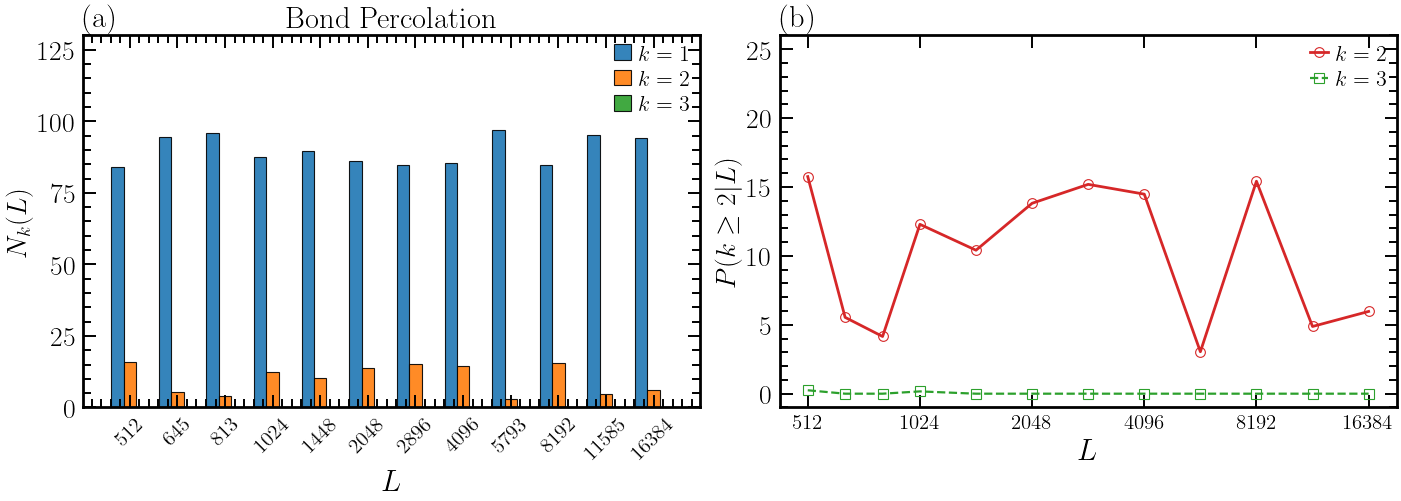

In [9]:
fig_bond, axes_bond = plot_cluster_count_distribution_all_L(
    df_clusters, perc_type="bond", figsize=(14, 5.0)
)
plt.savefig(f"{results_folder}/cluster_count_distribution_bond.pdf", dpi=300, bbox_inches="tight")
plt.show()


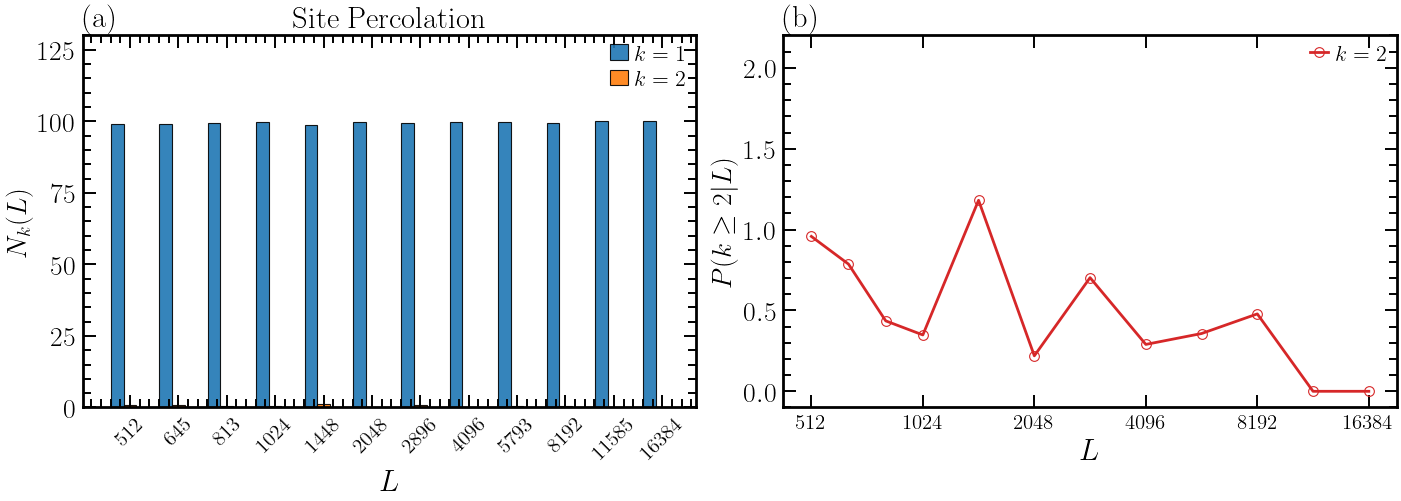

In [10]:
fig_node, axes_node = plot_cluster_count_distribution_all_L(
    df_clusters, perc_type="node", figsize=(14, 5.0)
)
plt.savefig(f"{results_folder}/cluster_count_distribution_node.pdf", dpi=300, bbox_inches="tight")
plt.show()


## 2. Largest Spanning Cluster Fraction across Different $L$

Finite-size scaling of the largest spanning cluster:
- Site fraction: $S_1 / L^2$
- Bond fraction: $E_1 / E_{\mathrm{total}}$


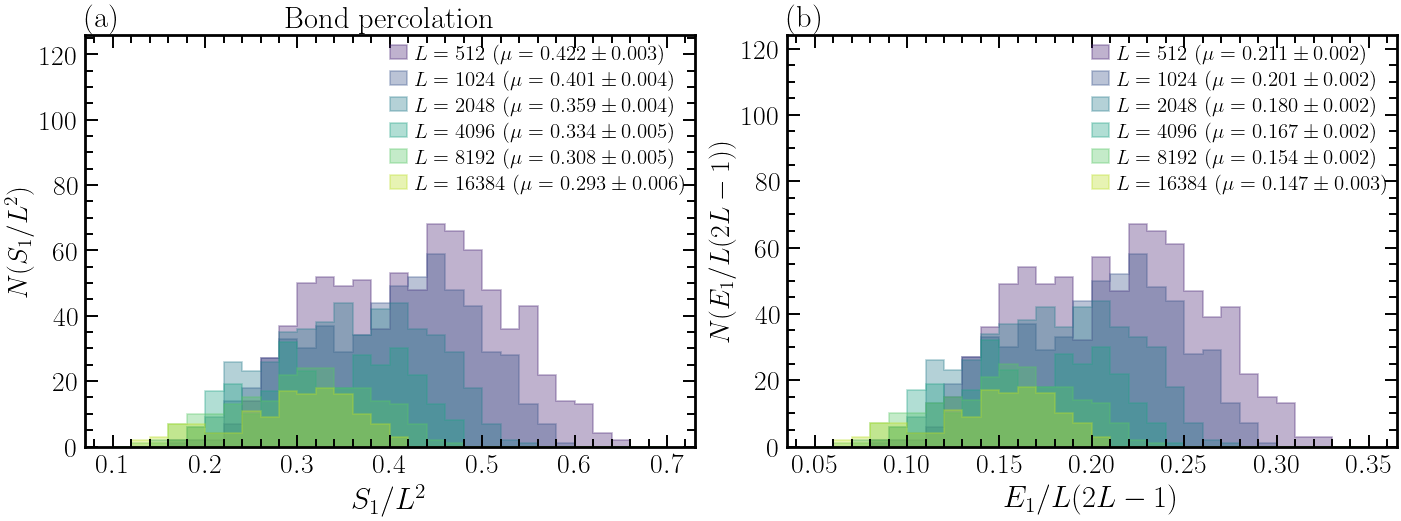

In [11]:
fig_bond_comb, axes_bc = plot_largest_cluster_bond_combined(
    df_clusters,
    L_subset=[512, 1024, 2048, 4096, 8192, 16384],
    figsize=(14, 5.2)
)
plt.savefig(f"{results_folder}/largest_cluster_bond.pdf", dpi=300, bbox_inches="tight")
plt.show()


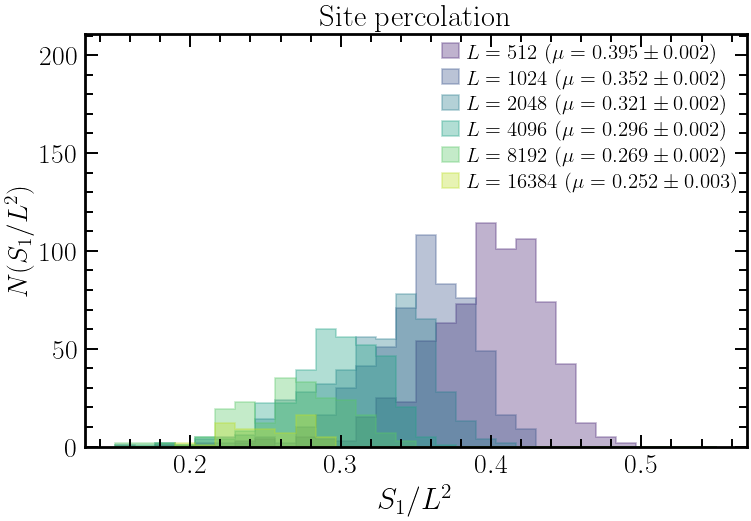

In [12]:
fig_node_comb, ax_nc = plot_largest_cluster_node_combined(
    df_clusters,
    L_subset=[512, 1024, 2048, 4096, 8192, 16384],
    figsize=(7.5, 5.2)
)
plt.savefig(f"{results_folder}/largest_cluster_node.pdf", dpi=300, bbox_inches="tight")
plt.show()


## 3. Cluster Fractions by Multiplicity Regime ($k = 1, 2, 3$)

To avoid squashing and overlay confusion, distributions are separated into distinct subplots for:
- **$k = 1$**: Single spanning cluster ($P_1$)
- **$k = 2$**: Two coexisting spanning clusters ($P_1$ and $P_2$)
- **$k = 3$**: Three coexisting spanning clusters ($P_1, P_2, P_3$)


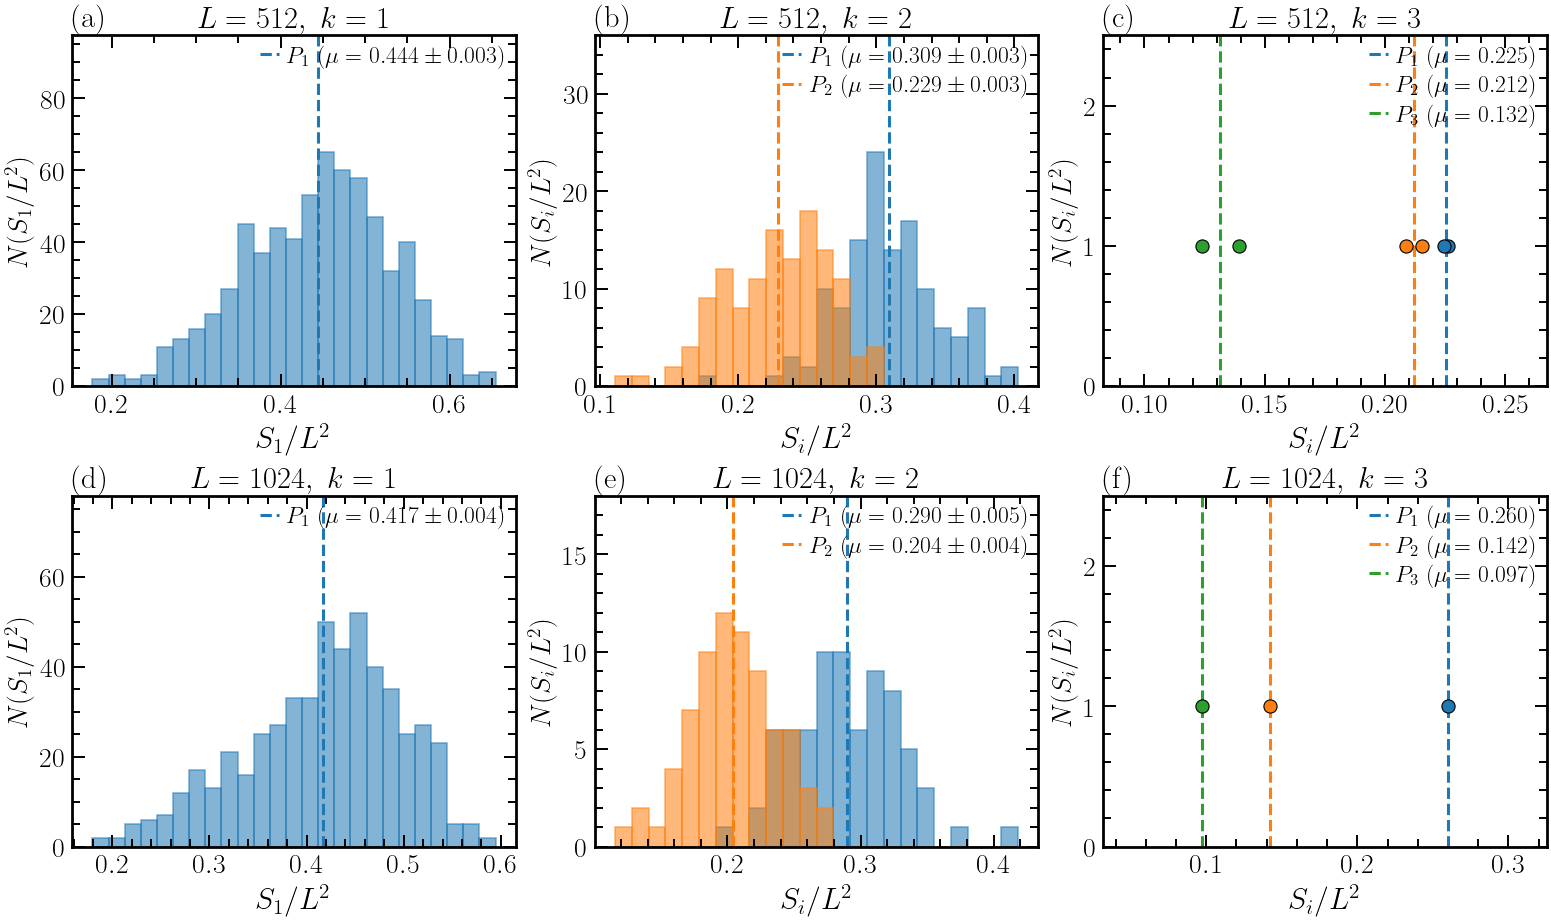

In [13]:
fig_sep, axes_sep = plot_cluster_regimes_separated(
    df_clusters,
    L_list=[512, 1024],
    perc_type="bond",
    figsize=(15.5, 9.2)
)
plt.savefig(f"{results_folder}/cluster_regimes_separated.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
stats_by_k = (
    df_clusters[df_clusters["type"] == "bond"]
    .groupby(["L", "k"])[
        [
            "c1_frac_site",
            "c2_frac_site",
            "c3_frac_site",
            "c1_frac_rel_site",
            "c2_frac_rel_site",
            "c3_frac_rel_site",
        ]
    ]
    .mean()
    .round(4)
)

print("Mean cluster fractions by lattice size L and multiplicity k (Bond Percolation):")
display(stats_by_k.loc[[512, 1024, 2048]])


Mean cluster fractions by lattice size L and multiplicity k (Bond Percolation):


c1_frac_site  c2_frac_site  c3_frac_site  c1_frac_rel_site  \
L    k                                                               
512  1        0.4439           NaN           NaN            0.7296   
     2        0.3089        0.2289           NaN            0.5021   
     3        0.2254        0.2121        0.1315            0.3565   
1024 1        0.4168           NaN           NaN            0.7491   
     2        0.2897        0.2041           NaN            0.5192   
     3        0.2601        0.1421        0.0971            0.4760   
2048 1        0.3759           NaN           NaN            0.7403   
     2        0.2566        0.1867           NaN            0.5056   

        c2_frac_rel_site  c3_frac_rel_site  
L    k                                      
512  1               NaN               NaN  
     2            0.3713               NaN  
     3            0.3354            0.2079  
1024 1               NaN               NaN  
     2            0.3660               NaN  
     3            0.2601            0.1777  
2048 1               NaN               NaN  
     2            0.3686               NaN

## 4. Relative Mass Partition: $S_i / S_{\mathrm{active}}$

Fraction of active mass in the slab occupied by each cluster:
$$s_i = \frac{S_i}{S_{\mathrm{active}}}$$


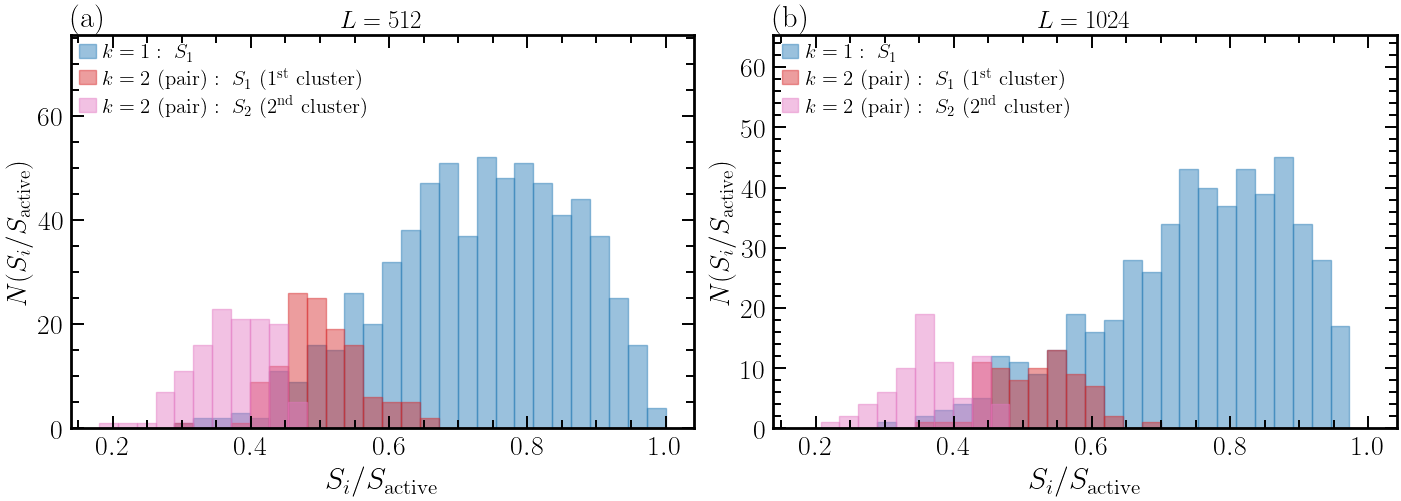

In [15]:
fig_rel, axes_rel = plot_relative_cluster_mass_fractions(
    df_clusters,
    L_list=[512, 1024],
    figsize=(14, 5.0)
)
plt.savefig(f"{results_folder}/relative_cluster_mass_fractions.pdf", dpi=300, bbox_inches="tight")
plt.show()


## 5. Summary

1. **Multiplicity Distribution**:
   - In bond percolation, $k = 1$ accounts for $84\%-97\%$ of samples, $k = 2$ accounts for $3\%-16\%$, and $k = 3$ appears in small lattices ($L = 512, 1024$).
   - In node percolation, configurations are overwhelmingly single-cluster ($k = 1$, $>99\%$), with rare $k = 2$ and no $k = 3$.

2. **Cluster Mass Partitioning**:
   - When multiple spanning clusters coexist, the active mass is split competitively between them rather than being dominated by a single giant component.
